In [1]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense
from sklearn.model_selection import train_test_split
import re
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords

In [2]:
# Download required NLTK libraries
nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\LENOVO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [3]:
# Load dataset
try:
    df = pd.read_csv(r"C:\Users\LENOVO\OneDrive\Documents\Reviews.csv").head(500)  
except FileNotFoundError:
    print("Error: Dataset file not found. Please check the file path.")
    exit()

In [4]:
# Display dataset information
print("Dataset preview:")
print(df.head())

Dataset preview:
   Id   ProductId          UserId                      ProfileName  \
0   1  B001E4KFG0  A3SGXH7AUHU8GW                       delmartian   
1   2  B00813GRG4  A1D87F6ZCVE5NK                           dll pa   
2   3  B000LQOCH0   ABXLMWJIXXAIN  Natalia Corres "Natalia Corres"   
3   4  B000UA0QIQ  A395BORC6FGVXV                             Karl   
4   5  B006K2ZZ7K  A1UQRSCLF8GW1T    Michael D. Bigham "M. Wassir"   

   HelpfulnessNumerator  HelpfulnessDenominator  Score        Time  \
0                     1                       1      5  1303862400   
1                     0                       0      1  1346976000   
2                     1                       1      4  1219017600   
3                     3                       3      2  1307923200   
4                     0                       0      5  1350777600   

                 Summary                                               Text  
0  Good Quality Dog Food  I have bought several of the Vitality

In [5]:
# Clean text function
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """Function to clean text: lowercasing, removing non-alphabetic characters, and stopwords."""
    text = text.lower()  # Convert text to lowercase
    text = re.sub(r'[^a-zA-Z\s]', '', text)  # Remove non-alphabetical characters
    words = nltk.word_tokenize(text)  # Tokenize text
    text = ' '.join([word for word in words if word not in stop_words])  # Remove stopwords
    return text

In [6]:
# Apply cleaning function
df['clean_text'] = df['Text'].astype(str).apply(clean_text)


In [7]:
# Convert star ratings to binary sentiment labels
df['sentiment'] = df['Score'].apply(lambda x: 1 if x > 3 else 0)

In [8]:
# Convert text into numerical sequences
print("Tokenizing and converting text into numerical sequences...")
tokenizer = Tokenizer(num_words=5000)
tokenizer.fit_on_texts(df['clean_text'])
sequences = tokenizer.texts_to_sequences(df['clean_text'])
X = pad_sequences(sequences, maxlen=100)
y = np.array(df['sentiment'])

Tokenizing and converting text into numerical sequences...


In [9]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [10]:
# Display data shapes
print(f"Training data shape: {X_train.shape}, Testing data shape: {X_test.shape}")

Training data shape: (400, 100), Testing data shape: (100, 100)


In [12]:
# Build RNN model using LSTM
print("Building the RNN model using LSTM...")
model = Sequential([
    Embedding(input_dim=5000, output_dim=32),
    LSTM(32, return_sequences=False),
    Dense(1, activation='sigmoid')
])

Building the RNN model using LSTM...


In [13]:
# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

In [14]:
# Train the model
print("Training the model...")
history = model.fit(X_train, y_train, epochs=5, batch_size=32, validation_data=(X_test, y_test))

Training the model...
Epoch 1/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 38ms/step - accuracy: 0.7018 - loss: 0.6799 - val_accuracy: 0.8100 - val_loss: 0.6173
Epoch 2/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8523 - loss: 0.5460 - val_accuracy: 0.8100 - val_loss: 0.5031
Epoch 3/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8142 - loss: 0.4726 - val_accuracy: 0.8100 - val_loss: 0.4918
Epoch 4/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.8192 - loss: 0.4440 - val_accuracy: 0.8100 - val_loss: 0.4895
Epoch 5/5
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8200 - loss: 0.4145 - val_accuracy: 0.8100 - val_loss: 0.4852


In [15]:
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test)
print(f"Model accuracy on test data: {accuracy:.2f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8084 - loss: 0.4839
Model accuracy on test data: 0.81


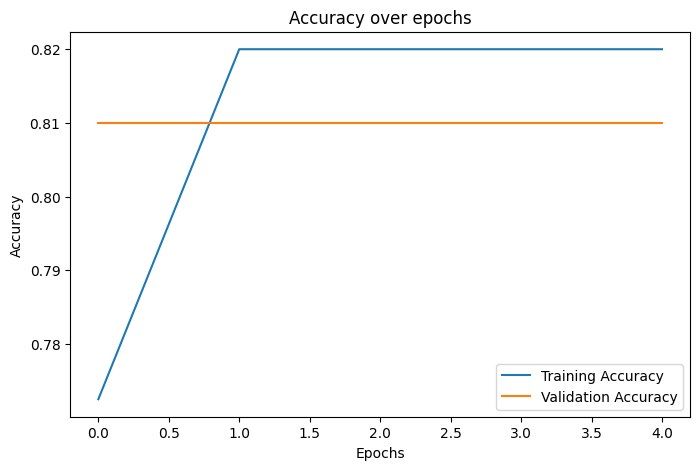

In [16]:
# Plot training accuracy and validation accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy over epochs')
plt.show()

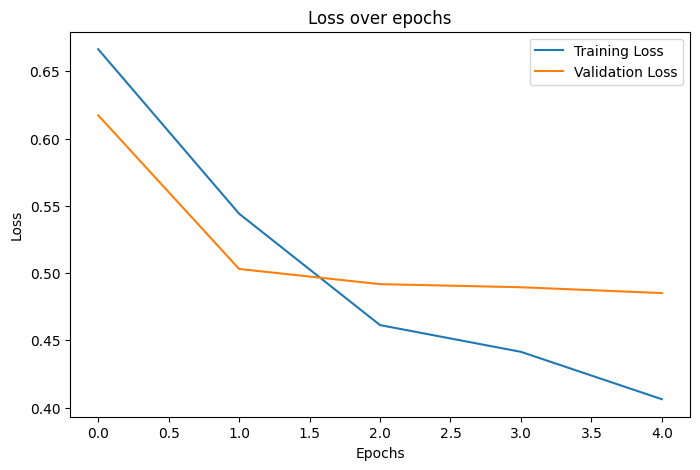

In [17]:
# Plot training loss and validation loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss over epochs')
plt.show()

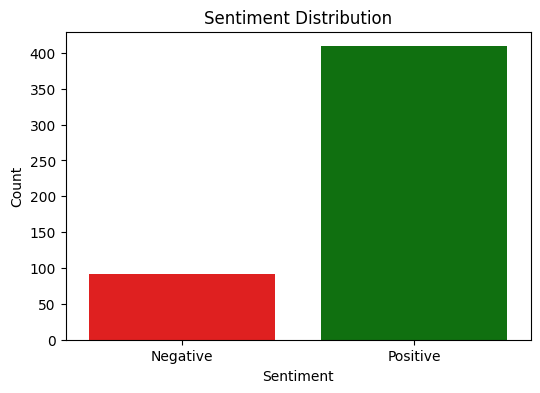

In [19]:
# Display sentiment distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='sentiment', hue='sentiment', palette=['red', 'green'], legend=False)
plt.xticks([0, 1], ['Negative', 'Positive'])
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Count")
plt.show()

In [20]:
# Show dataset with sentiment labels
print("Dataset with Sentiment Labels:")
print(df[['Text', 'clean_text', 'Score', 'sentiment']].head(20))

Dataset with Sentiment Labels:
                                                 Text  \
0   I have bought several of the Vitality canned d...   
1   Product arrived labeled as Jumbo Salted Peanut...   
2   This is a confection that has been around a fe...   
3   If you are looking for the secret ingredient i...   
4   Great taffy at a great price.  There was a wid...   
5   I got a wild hair for taffy and ordered this f...   
6   This saltwater taffy had great flavors and was...   
7   This taffy is so good.  It is very soft and ch...   
8   Right now I'm mostly just sprouting this so my...   
9   This is a very healthy dog food. Good for thei...   
10  I don't know if it's the cactus or the tequila...   
11  One of my boys needed to lose some weight and ...   
12  My cats have been happily eating Felidae Plati...   
13  good flavor! these came securely packed... the...   
14  The Strawberry Twizzlers are my guilty pleasur...   
15  My daughter loves twizzlers and this shipment ...   
